# Laboratorio 11. Redes convolucionales

LeNet para MNIST, una variante para CIFAR 100 y VGG16 con pesos de ImageNet. Los datos y pesos se descargan al ejecutar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

keras.utils.set_random_seed(42)

def curvas(historia):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, variable in zip(axes, ['loss', 'accuracy']):
        ax.plot(historia.history[variable], label='Entrenamiento')
        ax.plot(historia.history['val_' + variable], label='Validación')
        ax.set(xlabel='Época', ylabel=variable)
        ax.legend()
    plt.tight_layout()
    plt.show()

I0000 00:00:1794920989.194442    5356 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794920990.050964    5356 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794920997.581458    5356 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 1. MNIST y LeNet

Normalizo a [0,1], agrego el canal de grises y reservo 30 % para validación. Uso 6 y 16 filtros, pooling y capas densas de 120, 84 y 10 neuronas. El relleno con ceros lleva las imágenes a 32×32; adapto LeNet con ReLU.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 7s 1us/step


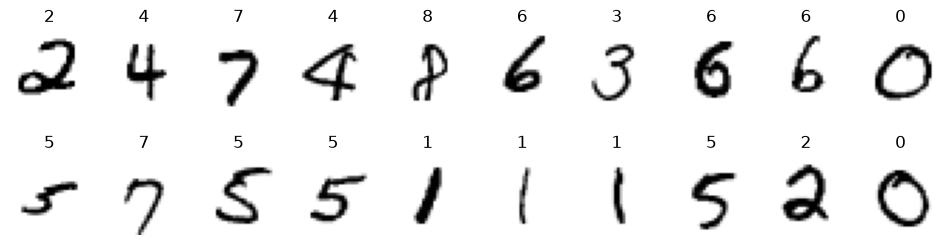

E0000 00:00:1794908247.720636 2146816 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ zero_padding2d (ZeroPadding2D)  │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


W0000 00:00:1794908249.256185 2146816 cpu_allocator_impl.cc:174] Allocation of 131712000 exceeds 10% of free system memory.
W0000 00:00:1794908251.970884 2148424 cpu_allocator_impl.cc:174] Allocation of 24840000 exceeds 10% of free system memory.
W0000 00:00:1794908251.972827 2148431 cpu_allocator_impl.cc:174] Allocation of 24840000 exceeds 10% of free system memory.
W0000 00:00:1794908251.987861 2148428 cpu_allocator_impl.cc:174] Allocation of 25244800 exceeds 10% of free system memory.
W0000 00:00:1794908252.073634 2148431 cpu_allocator_impl.cc:174] Allocation of 24840000 exceeds 10% of free system memory.


329/329 - 37s - 113ms/step - accuracy: 0.8699 - loss: 0.4364 - val_accuracy: 0.9548 - val_loss: 0.1504
Epoch 2/10
329/329 - 13s - 40ms/step - accuracy: 0.9659 - loss: 0.1149 - val_accuracy: 0.9703 - val_loss: 0.0971
Epoch 3/10
329/329 - 14s - 42ms/step - accuracy: 0.9759 - loss: 0.0795 - val_accuracy: 0.9758 - val_loss: 0.0775
Epoch 4/10
329/329 - 16s - 48ms/step - accuracy: 0.9809 - loss: 0.0632 - val_accuracy: 0.9806 - val_loss: 0.0633
Epoch 5/10
329/329 - 35s - 107ms/step - accuracy: 0.9835 - loss: 0.0527 - val_accuracy: 0.9826 - val_loss: 0.0585
Epoch 6/10
329/329 - 15s - 46ms/step - accuracy: 0.9863 - loss: 0.0448 - val_accuracy: 0.9834 - val_loss: 0.0558
Epoch 7/10
329/329 - 11s - 34ms/step - accuracy: 0.9882 - loss: 0.0389 - val_accuracy: 0.9836 - val_loss: 0.0545
Epoch 8/10
329/329 - 13s - 40ms/step - accuracy: 0.9891 - loss: 0.0343 - val_accuracy: 0.9838 - val_loss: 0.0534
Epoch 9/10
329/329 - 30s - 92ms/step - accuracy: 0.9907 - loss: 0.0300 - val_accuracy: 0.9851 - val_loss:

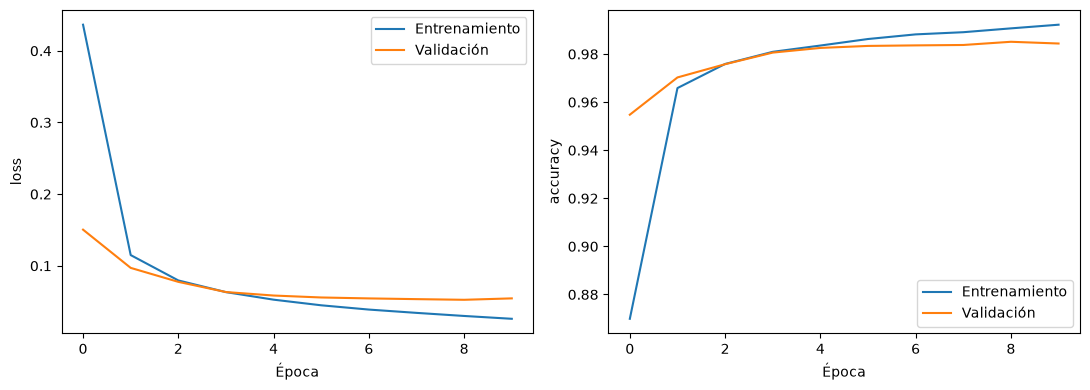

In [2]:
# Cargamos las particiones oficiales y separamos validación dentro de entrenamiento.
(imagenes, etiquetas), (X_test, y_test) = keras.datasets.mnist.load_data()
imagenes = imagenes.astype('float32')[..., None] / 255.
X_test = X_test.astype('float32')[..., None] / 255.
X_train, X_val, y_train, y_val = train_test_split(imagenes, etiquetas,
    test_size=.3, stratify=etiquetas, random_state=42)
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for ax, imagen, etiqueta in zip(axes.ravel(), X_train[:20], y_train[:20]):
    ax.imshow(imagen.squeeze(), cmap='binary')
    ax.set_title(str(etiqueta))
    ax.axis('off')
plt.show()

# Las convoluciones aprenden rasgos locales y el pooling reduce la resolución.
keras.backend.clear_session()
lenet = keras.Sequential([
    keras.Input(shape=(28, 28, 1)), keras.layers.ZeroPadding2D(2),
    keras.layers.Conv2D(6, 5, activation='relu'), keras.layers.AveragePooling2D(2),
    keras.layers.Conv2D(16, 5, activation='relu'), keras.layers.AveragePooling2D(2),
    keras.layers.Flatten(), keras.layers.Dense(120, activation='relu'),
    keras.layers.Dense(84, activation='relu'), keras.layers.Dense(10, activation='softmax')])
lenet.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
lenet.summary()
historia_mnist = lenet.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=10, batch_size=128, verbose=2)
curvas(historia_mnist)

In [3]:
# Cada fila de q contiene diez probabilidades; argmax elige el dígito.
q = lenet.predict(X_test, batch_size=256, verbose=0)
pred = q.argmax(axis=1)
display(pd.DataFrame(q[:5], columns=range(10)))
print('Predicciones:', pred[:5], '| etiquetas:', y_test[:5])
print(classification_report(y_test, pred, zero_division=0))
print('Métricas MNIST:', lenet.evaluate(X_test, y_test, verbose=0, return_dict=True))

,0,1,2,3,4,5,6,7,8,9
0,8.549804e-09,2.158673e-08,2.197900e-07,4.430784e-06,2.828594e-09,1.664489e-08,1.631344e-14,9.999817e-01,5.340118e-08,1.351051e-05
1,2.852282e-08,6.171447e-04,9.993812e-01,2.078214e-08,2.744848e-09,2.461631e-12,3.114411e-09,1.745225e-08,1.489441e-06,4.695623e-13
2,2.332186e-07,9.999706e-01,1.166047e-07,3.572683e-07,2.360656e-05,1.009352e-08,6.049750e-07,1.376069e-06,2.665337e-06,2.938747e-07
3,9.999885e-01,1.693497e-09,1.043241e-06,4.984920e-10,2.627206e-08,9.742400e-07,9.458236e-06,2.428295e-08,1.133416e-08,2.793720e-08
4,1.861140e-08,6.557851e-06,6.483869e-09,3.146426e-07,9.994033e-01,2.332987e-07,8.075287e-07,2.167439e-06,1.365583e-07,5.863361e-04


Predicciones: [7 2 1 0 4] | etiquetas: [7 2 1 0 4]
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       1.00      0.98      0.99      1032
           3       0.99      0.98      0.99      1010
           4       0.99      0.98      0.99       982
           5       0.98      0.99      0.98       892
           6       0.99      0.98      0.99       958
           7       0.99      0.98      0.98      1028
           8       0.99      0.98      0.99       974
           9       0.96      0.99      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

Métricas MNIST: {'accuracy': 0.9861999750137329, 'loss': 0.043850127607584}


## 2. CIFAR 100

Son imágenes de tres canales y cien clases. Mantengo dos convoluciones, con BatchNormalization antes de ReLU y dropout después del pooling. Elijo la época con validación.

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 3063s 18us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 6)      │           450 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 6)      │            24 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 16)     │         2,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 10, 10, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 10, 10, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       102,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 84)             │        21,588 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 100)            │         8,500 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 135,682 (530.01 KB)

 Trainable params: 135,638 (529.84 KB)

 Non-trainable params: 44 (176.00 B)

Epoch 1/30
625/625 - 20s - 32ms/step - accuracy: 0.0666 - loss: 4.1739 - val_accuracy: 0.1007 - val_loss: 3.8880
Epoch 2/30
625/625 - 17s - 27ms/step - accuracy: 0.1303 - loss: 3.6979 - val_accuracy: 0.1632 - val_loss: 3.4929
Epoch 3/30
625/625 - 23s - 38ms/step - accuracy: 0.1641 - loss: 3.4989 - val_accuracy: 0.1916 - val_loss: 3.3712
Epoch 4/30
625/625 - 23s - 38ms/step - accuracy: 0.1838 - loss: 3.3835 - val_accuracy: 0.1788 - val_loss: 3.4102
Epoch 5/30
625/625 - 15s - 25ms/step - accuracy: 0.1969 - loss: 3.2968 - val_accuracy: 0.2012 - val_loss: 3.2885
Epoch 6/30
625/625 - 18s - 29ms/step - accuracy: 0.2102 - loss: 3.2270 - val_accuracy: 0.2279 - val_loss: 3.1607
Epoch 7/30
625/625 - 29s - 46ms/step - accuracy: 0.2192 - loss: 3.1768 - val_accuracy: 0.2250 - val_loss: 3.1362
Epoch 8/30
625/625 - 20s - 32ms/step - accuracy: 0.2270 - loss: 3.1264 - val_accuracy: 0.2242 - val_loss: 3.1822
Epoch 9/30
625/625 - 16s - 25ms/step - accuracy: 0.2333 - loss: 3.0921 - val_accuracy: 0.2242 - 

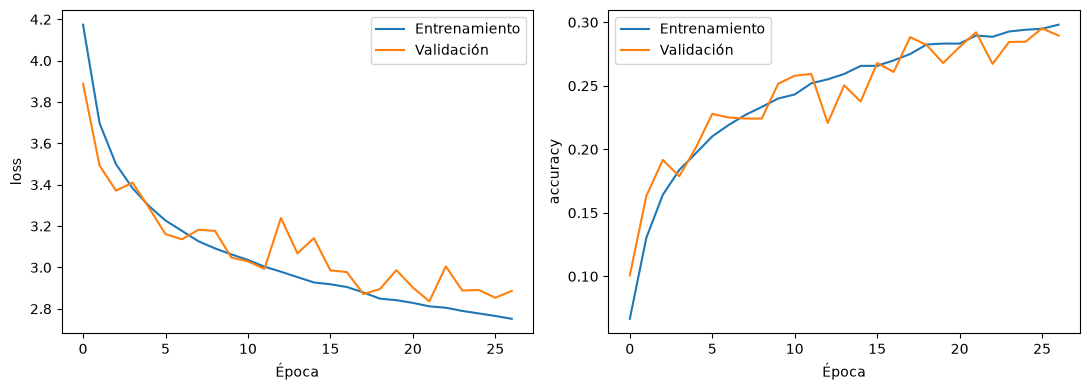

Métricas CIFAR-100: {'accuracy': 0.29109999537467957, 'loss': 2.8110387325286865}
Accuracy top-5: 0.5975


In [4]:
(imagenes, etiquetas), (X_test_c, y_test_c) = keras.datasets.cifar100.load_data(label_mode='fine')
imagenes = imagenes.astype('float32') / 255.
X_test_c = X_test_c.astype('float32') / 255.
etiquetas = etiquetas.ravel()
y_test_c = y_test_c.ravel()
X_train_c, X_val_c, y_train_c, y_val_c = train_test_split(imagenes, etiquetas,
    test_size=.2, stratify=etiquetas, random_state=42)

modelo_cifar = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(6, 5, use_bias=False), keras.layers.BatchNormalization(),
    keras.layers.Activation('relu'), keras.layers.MaxPooling2D(2), keras.layers.Dropout(.2),
    keras.layers.Conv2D(16, 5, use_bias=False), keras.layers.BatchNormalization(),
    keras.layers.Activation('relu'), keras.layers.MaxPooling2D(2), keras.layers.Dropout(.2),
    keras.layers.Flatten(), keras.layers.Dense(256, activation='relu'),
    keras.layers.Dropout(.3), keras.layers.Dense(84, activation='relu'),
    keras.layers.Dense(100, activation='softmax')])
modelo_cifar.compile(optimizer='nadam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
modelo_cifar.summary()
parada = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
historia_cifar = modelo_cifar.fit(X_train_c, y_train_c,
    validation_data=(X_val_c, y_val_c), epochs=30, batch_size=64, callbacks=[parada], verbose=2)
curvas(historia_cifar)
print('Métricas CIFAR-100:', modelo_cifar.evaluate(X_test_c, y_test_c, verbose=0, return_dict=True))
q_cifar = modelo_cifar.predict(X_test_c, batch_size=256, verbose=0)
print('Accuracy top-5:', np.mean(np.any(np.argsort(q_cifar, axis=1)[:, -5:] == y_test_c[:, None], axis=1)))

CIFAR 100 tiene más clases y mayor dificultad que MNIST. Reviso las curvas de entrenamiento y validación para identificar sobreajuste.

## 3. VGG16 preentrenada

Clasifico dos imágenes de elefantes con VGG16 sin reentrenar. La imagen africana usa la copia del material complementario del curso. La preparación recibe intensidades en [0,255], cambia RGB a BGR y centra los canales; aquí no divido por 255.

E0000 00:00:1794921001.602099    5356 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50

W0000 00:00:1794921002.538037    5356 cpu_allocator_impl.cc:174] Allocation of 411041792 exceeds 10% of free system memory.
W0000 00:00:1794921003.279459    5356 cpu_allocator_impl.cc:174] Allocation of 411041792 exceeds 10% of free system memory.
W0000 00:00:1794921003.496550    5356 cpu_allocator_impl.cc:174] Allocation of 411041792 exceeds 10% of free system memory.
W0000 00:00:1794921004.555758    5356 cpu_allocator_impl.cc:174] Allocation of 67108864 exceeds 10% of free system memory.
W0000 00:00:1794921004.608273    5356 cpu_allocator_impl.cc:174] Allocation of 67108864 exceeds 10% of free system memory.


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


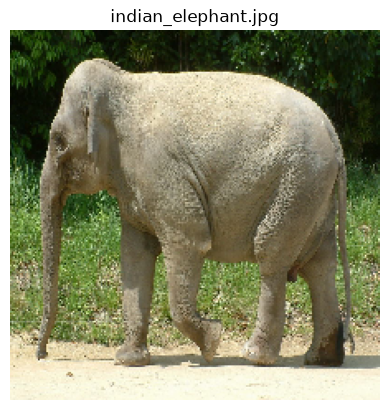

,id,clase,probabilidad
0,n02504013,Indian_elephant,0.719422
1,n02504458,African_elephant,0.241411
2,n01871265,tusker,0.036276


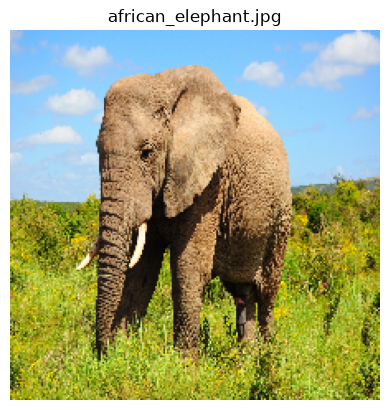

,id,clase,probabilidad
0,n02504458,African_elephant,0.755155
1,n01871265,tusker,0.203762
2,n02504013,Indian_elephant,0.041082


In [2]:
from pathlib import Path
from urllib.request import Request, urlopen

urls = {
    'indian_elephant.jpg': 'https://upload.wikimedia.org/wikipedia/commons/f/f9/Zoorashia_elephant.jpg',
    'african_elephant.jpg': 'https://raw.githubusercontent.com/ssanchezgoe/diplomado_udea/master/image/african_elephant_bull.jpg'}
cache = Path.home() / '.keras' / 'datasets'
cache.mkdir(parents=True, exist_ok=True)
vgg = keras.applications.VGG16(weights='imagenet', include_top=True)
vgg.summary()
for nombre, url in urls.items():
    ruta = cache / ('lab11_' + nombre)
    if not ruta.is_file() or ruta.stat().st_size == 0:
        solicitud = Request(url, headers={'User-Agent': 'MontoyaCourseNotebook/1.0 (educational image processing)'})
        with urlopen(solicitud, timeout=60) as respuesta:
            contenido = respuesta.read()
        ruta.write_bytes(contenido)
    imagen = keras.utils.load_img(ruta, target_size=(224, 224))
    entrada = keras.utils.img_to_array(imagen)[None, ...]
    entrada = keras.applications.vgg16.preprocess_input(entrada)
    salida = vgg.predict(entrada, verbose=0)
    top3 = keras.applications.vgg16.decode_predictions(salida, top=3)[0]
    plt.imshow(imagen)
    plt.axis('off')
    plt.title(nombre)
    plt.show()
    display(pd.DataFrame(top3, columns=['id', 'clase', 'probabilidad']))